# Lab I: Mach Zehnder Interferometer

**Name: Andrés Sanchez-Toril**

In [2]:
%pip install numpy matplotlib pandas scipy

   ---------------------------------------- 0.0/12.4 MB ? eta -:--:--
    --------------------------------------- 0.3/12.4 MB ? eta -:--:--
   -- ------------------------------------- 0.8/12.4 MB 2.6 MB/s eta 0:00:05
   --- ------------------------------------ 1.0/12.4 MB 2.0 MB/s eta 0:00:06
   ---- ----------------------------------- 1.3/12.4 MB 1.9 MB/s eta 0:00:06
   ----- ---------------------------------- 1.8/12.4 MB 1.8 MB/s eta 0:00:06
   ------ --------------------------------- 2.1/12.4 MB 1.9 MB/s eta 0:00:06
   ------- -------------------------------- 2.4/12.4 MB 1.9 MB/s eta 0:00:06
   --------- ------------------------------ 2.9/12.4 MB 1.8 MB/s eta 0:00:06
   ---------- ----------------------------- 3.1/12.4 MB 1.8 MB/s eta 0:00:06
   ---------- ----------------------------- 3.4/12.4 MB 1.8 MB/s eta 0:00:05
   ------------ --------------------------- 3.9/12.4 MB 1.8 MB/s eta 0:00:05
   ------------- -------------------------- 4.2/12.4 MB 1.7 MB/s eta 0:00:05
   ----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


# **Introduction**

In this practice, we will focus on the **Mach-Zehnder Interferometer (MZI)**, a fundamental building block in photonic circuits. Our objective is to study the basic operation of the MZI, develop its mathematical model, and analyze its behavior under common real-world conditions.

Throughout the exercises, we will examine the configuration of the MZI and simulate typical issues such as phase mismatches and optical attenuation. This approach will provide insights into the challenges of practical implementations and the performance of photonic systems.

## **Main Objectives:**
- Understand the operating principle of an MZI.
- Develop a mathematical model of the interferometer.
- Simulate errors like phase mismatches and attenuation.
- Analyze the impact of these errors on system performance.
- Use experimental data to control the MZI.


# **Section I: Mach-Zehnder Interferometer (MZI) Transfer Function**  

## **Objective**  
The goal of this section is to program the transfer function of the Mach-Zehnder Interferometer (MZI), a basic building block in photonic circuits. We will model the MZI as a combination of two Multi-Mode Interference (MMI) couplers and a phase shifter.  

---

## **MZI Structure**  

A symmetric MZI consists of two MMI couplers connected by two optical waveguides. One of the waveguides includes a phase shifter that applies a phase shift $\phi$. The general structure is illustrated below, including a phase shifter on the top and bottom arms:  

![MZI Structure](images/mzi.png)  

In the following exercises, we will focus on the MZI with only one phase shifter, unless explicitly stated otherwise.

---

## **Transfer Matrix Model**  

The transfer function of an MZI can be expressed using its transfer matrix representation. Each MMI coupler is modeled as a unitary matrix $M_{\text{MMI}}$, while the phase shifter is represented by a diagonal matrix $P(\phi)$.  

### **Transfer Matrix Definition:**  

$
M_{\text{MMI}} = \frac{1}{\sqrt{2}} \begin{bmatrix} 
1 & i \\
i & 1 
\end{bmatrix}
$

$
P(\phi) = \begin{bmatrix} 
e^{i \phi} & 0 \\
0 & 1 
\end{bmatrix}
$

The MZI transfer matrix $M_{\text{MZI}}$ is computed as:  

$
M_{\text{MZI}} = M_{\text{MMI}} \cdot P(\phi) \cdot M_{\text{MMI}}
$


## **Exercise 1: Transfer Functions of MZI Components**  

### **Objective:**  
- Define the transfer functions of each MZI component: the MMI and the phase shifter.  
- Compute the overall transfer function of the MZI.  
- Plot the MZI’s response for a phase range from 0 to $2\pi$ in both linear and decibel (dB) scales.  

---


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Define the MMI transfer matrix
def MMI():
    
    return np.array([ [1, 1j], [1j, 1]])*(1/np.sqrt(2))

# Define the phase shifter transfer matrix
def phase_shifter(phi):
    return np.array([ [np.exp(1j*phi), 0], [0, 1]])

# Define the MZI transfer function
def MZI(phi):
    return MMI() @ phase_shifter(phi) @ MMI()


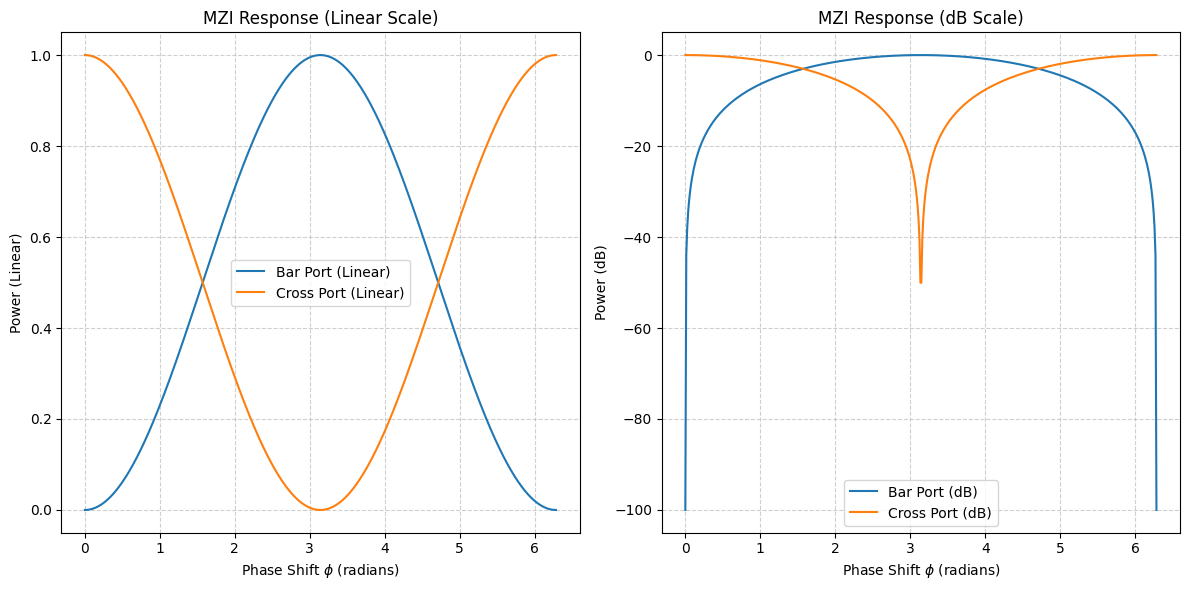

In [4]:
# Define phase range from 0 to 2π
phi_range = np.linspace(0, 2*np.pi, 500)

# Calculate output powers
# Extraemos el elemento [0,0] para el Bar Port y el [1,0] para el Cross Port, 
# asumiendo que la luz entra por el puerto superior, y calculamos la potencia (|E|^2).
bar_port = np.array([np.abs(MZI(phi)[0, 0])**2 for phi in phi_range])
cross_port = np.array([np.abs(MZI(phi)[1, 0])**2 for phi in phi_range])

# Convert to dB (avoid -inf by setting minimum value)
def to_db(power):
    return 10 * np.log10(np.maximum(power, 1e-10))

bar_port_db = to_db(bar_port)
cross_port_db = to_db(cross_port)

# Plot the response
plt.figure(figsize=(12, 6))

# Linear Scale Plot
plt.subplot(1, 2, 1)
plt.plot(phi_range, bar_port, label="Bar Port (Linear)")
plt.plot(phi_range, cross_port, label="Cross Port (Linear)")
plt.xlabel(r"Phase Shift $\phi$ (radians)")
plt.ylabel("Power (Linear)")
plt.title("MZI Response (Linear Scale)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

# dB Scale Plot
plt.subplot(1, 2, 2)
plt.plot(phi_range, bar_port_db, label="Bar Port (dB)")
plt.plot(phi_range, cross_port_db, label="Cross Port (dB)")
plt.xlabel(r"Phase Shift $\phi$ (radians)")
plt.ylabel("Power (dB)")
plt.title("MZI Response (dB Scale)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

## **Exercise 2: Introducing Errors to MZI Components**  


### **MMI Transfer Matrix with Errors**  

In the ideal case, the MMI matrix is:

$
M_{\text{MMI}} = \frac{1}{\sqrt{2}} \begin{bmatrix} 
1 & i \\
i & 1 
\end{bmatrix}
$

To introduce errors, we modify the elements of the MMI matrix. The modified matrix with errors, denoted as $M_{\text{MMI}}$($\alpha$), is given by:

$
M_{\text{MMI}}(\alpha) = \begin{bmatrix} 
\sin\left(\frac{\pi}{4} + \alpha \right) & i \cos\left(\frac{\pi}{4} + \alpha \right) \\
i \cos\left(\frac{\pi}{4} + \alpha \right) & \sin\left(\frac{\pi}{4} + \alpha \right)
\end{bmatrix}
$

where $\alpha$ represents the deviation from the ideal performance of the MMI. It can be seen that when $\alpha = 0$, we recover the transfer matrix used in the previous example. This deviation from ideal performance is a consequence of discrepancies between the design and the fabricated device.

---

### **Phase Shifter with Errors**  

Similarly, to introduce errors in the phase shifter, we modify the phase shift by introducing a deviation $\delta$, resulting in a new phase shift $\phi_{\text{eff}} = \phi + \delta $. The phase shifter matrix becomes:

$
P(\phi_{\text{eff}}) = \begin{bmatrix} 
e^{i (\phi + \delta)} & 0 \\
0 & 1 
\end{bmatrix}
$

---

### **Objective:**  
In this exercise, we will repeat the procedure from Exercise 1 but introduce errors to the building blocks of the MZI. These errors will simulate real-world imperfections that can occur in photonic devices.  
- We will modify the transfer matrix of the MMI coupler by introducing deviations in its elements.  
- We will also introduce errors to the phase shifters.  
- Plot the response for alpha = 0.05 and 0.15 and $\delta$ = 0.0.
- Plot the response for $\delta$ = 0.1, 0.5 and alpha = 0.0.



In [5]:
# Define the MMI transfer matrix with error (alpha deviation)
def MMI_with_error(alpha):
    sin_term = np.sin(np.pi/4 + alpha)
    cos_term = 1j * np.cos(np.pi/4 + alpha)
    return np.array([
        [sin_term, cos_term],
        [cos_term, sin_term]
    ])

# Define the phase shifter transfer matrix with error (delta deviation)
def phase_shifter_with_error(phi, delta):
    return np.array([
        [np.exp(1j * (phi + delta)), 0],
        [0, 1]
    ])

# Define the MZI transfer function with errors
def MZI_with_errors(phi, alpha, delta):
    return MMI_with_error(alpha) @ phase_shifter_with_error(phi, delta) @ MMI_with_error(alpha)

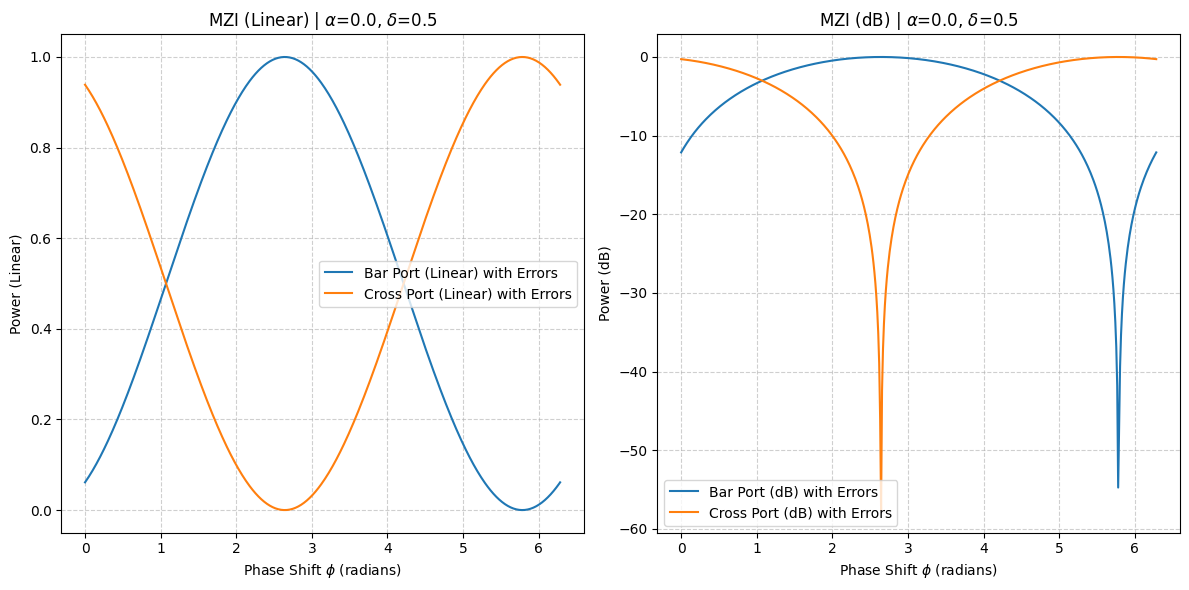

In [6]:
# Define phase range from 0 to 2π
phi_range = np.linspace(0, 2*np.pi, 500)

# Choose deviations for errors (Ejemplo: alpha = 0.05, delta = 0.0)
alpha = 0.0  # Deviation in MMI
delta = 0.5  # Deviation in phase shifter

# Calculate output powers with errors
# Extraemos el campo [0,0] para Bar y [1,0] para Cross, calculando la potencia (|E|^2)
bar_port_with_errors = np.array([np.abs(MZI_with_errors(phi, alpha, delta)[0, 0])**2 for phi in phi_range])
cross_port_with_errors = np.array([np.abs(MZI_with_errors(phi, alpha, delta)[1, 0])**2 for phi in phi_range])

# Convert to dB (avoid -inf by setting a minimum value)
def to_db(power):
    return 10 * np.log10(np.maximum(power, 1e-10))

bar_port_with_errors_db = to_db(bar_port_with_errors)
cross_port_with_errors_db = to_db(cross_port_with_errors)

# Plot the response with errors
plt.figure(figsize=(12, 6))

# Linear Scale Plot
plt.subplot(1, 2, 1)
plt.plot(phi_range, bar_port_with_errors, label="Bar Port (Linear) with Errors")
plt.plot(phi_range, cross_port_with_errors, label="Cross Port (Linear) with Errors")
plt.xlabel(r"Phase Shift $\phi$ (radians)")
plt.ylabel("Power (Linear)")
plt.title(f"MZI (Linear) | $\\alpha$={alpha}, $\\delta$={delta}")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

# dB Scale Plot
plt.subplot(1, 2, 2)
plt.plot(phi_range, bar_port_with_errors_db, label="Bar Port (dB) with Errors")
plt.plot(phi_range, cross_port_with_errors_db, label="Cross Port (dB) with Errors")
plt.xlabel(r"Phase Shift $\phi$ (radians)")
plt.ylabel("Power (dB)")
plt.title(f"MZI (dB) | $\\alpha$={alpha}, $\\delta$={delta}")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

### Provide some comments on how the MZI is affected by the introduction of errors:
--------------------------- Please write your comments below -------------------------------------
El introducir una diferencia de fase con delta provoca un shift horizontal en la función de transferencia del MZI. No obstante, el período, amplitud, y ER se mantienen igual. La única diferencia es que los puntos de transmisión máxima y mínima ocurren a distinta fase aplicada comparada al caso ideal.

Por otra parte, al error de acoplo (alpha), provoca que el MZI ya no actúe como un spliter 50/50 perfecto. Como hay un desbalanceo entre los dos brazos ya no ocurre interferencia destructiva perfecta, lo que degrada el ER. Visible en las gráficas, los niveles de potencia mínima son más altas, lo que quiere decir que hay luz que se filtra en puertos que tendrían que tener 0 potencia


## **Exercise 3: Introducing Losses to the MZI Components**  


### **Introducing Losses in the MZI Components**  

To introduce losses in the components, we apply an attenuation factor $ \eta $ (where $ 0 \leq \eta \leq 1 $). The value of $ \eta = 1 $ corresponds to no loss (ideal performance), and $ \eta < 1 $ represents the degree of loss in the system.  

For the MMI with losses, the transfer matrix becomes:

$$
M_{\text{MMI}}(\eta) = \frac{1}{\sqrt{2}} \begin{bmatrix} 
\eta & i\eta \\
i\eta & \eta 
\end{bmatrix}
$$

Similarly, for the phase shifter with losses, the transfer matrix becomes:

$$
P_{\text{loss}}(\phi) = \begin{bmatrix} 
\eta e^{i\phi} & 0 \\
0 & \eta 
\end{bmatrix}
$$
---

### **Objective:**  
In this exercise, we will repeat the procedure from Exercise 1, but this time we will introduce **losses** to the MZI components. These losses simulate attenuation that occurs due to imperfections in the system, such as absorption or scattering in the photonic components.  

- We will introduce losses in the MMI coupler and phase shifter.  
- We will calculate the MZI response considering these losses. 

Use $\eta$ = 0.8



In [7]:
# Define the MMI transfer matrix with losses (attenuation factor eta)
def MMI_with_losses(eta):
    return eta * np.array([[1, 1j], [1j, 1]]) * (1/np.sqrt(2))

# Define the phase shifter transfer matrix with losses (attenuation factor eta)
def phase_shifter_with_losses(phi, eta):
    return eta * np.array([[np.exp(1j * phi), 0], [0, 1]])

# Define the MZI transfer function with losses
def MZI_with_losses_func(phi, eta):
    # Multiplicamos: MMI -> Phase Shifter -> MMI
    return MMI_with_losses(eta) @ phase_shifter_with_losses(phi, eta) @ MMI_with_losses(eta)

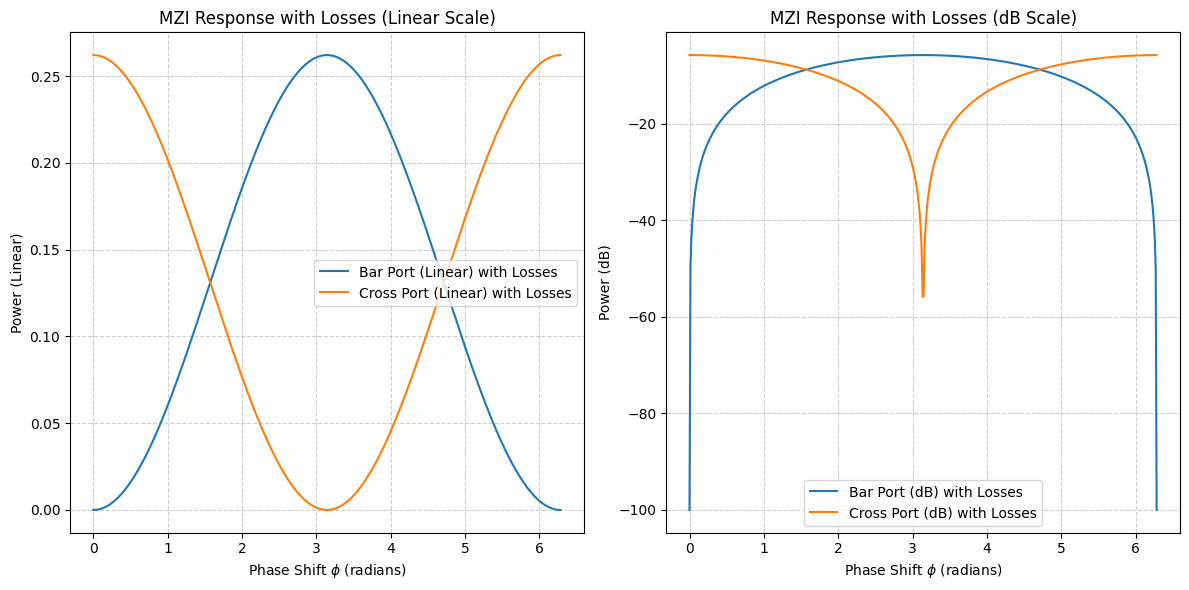

In [9]:
# Define phase range from 0 to 2π
phi_range = np.linspace(0, 2*np.pi, 500)

# Choose attenuation factor for losses
eta = 0.8  # Attenuation factor (losses in MMI and phase shifters)

# Calculate output powers with losses
bar_port_with_losses = np.array([np.abs(MZI_with_losses_func(phi, eta)[0, 0])**2 for phi in phi_range])
cross_port_with_losses = np.array([np.abs(MZI_with_losses_func(phi, eta)[1, 0])**2 for phi in phi_range])

# Convert to dB (avoid -inf by setting minimum value)
def to_db(power):
    return 10 * np.log10(np.maximum(power, 1e-10))

bar_port_with_losses_db = to_db(bar_port_with_losses)
cross_port_with_losses_db = to_db(cross_port_with_losses)


# Plot the response with losses
plt.figure(figsize=(12, 6))

# Linear Scale Plot
plt.subplot(1, 2, 1)
plt.plot(phi_range, bar_port_with_losses, label="Bar Port (Linear) with Losses")
plt.plot(phi_range, cross_port_with_losses, label="Cross Port (Linear) with Losses")
plt.xlabel(r"Phase Shift $\phi$ (radians)")
plt.ylabel("Power (Linear)")
plt.title("MZI Response with Losses (Linear Scale)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

# dB Scale Plot
plt.subplot(1, 2, 2)
plt.plot(phi_range, bar_port_with_losses_db, label="Bar Port (dB) with Losses")
plt.plot(phi_range, cross_port_with_losses_db, label="Cross Port (dB) with Losses")
plt.xlabel(r"Phase Shift $\phi$ (radians)")
plt.ylabel("Power (dB)")
plt.title("MZI Response with Losses (dB Scale)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

### Provide some comments on how the MZI is affected by the introduction of losses:
--------------------------- Please write your comments below -------------------------------------
Introducir un factor de atenuación resulta en una reducción de la potencia óptica total que se transmite a través del dispositivo. En lineal hay una disminución proporcional en la amplitud máxima de la señal mientras que en dB hay un desplazamiento hacia abajo de toda la función de transferencia.

Respecto a el ER, como los brazos están balanceados, no hay variación, lo único es que se transmite menos luz. Lo mismo ocurre con el período del patrón de interferencia.

## **Exercise 4: Calibration of the Thermo-Optic Phase Shifters in the MZI**

### **Calibrating the Phase in a Real Laboratory Environment**

In a real laboratory environment, the implementation of a phase in the Mach-Zehnder interferometer requires its calibration. In the case of thermo-optic phase shifters, there is a relationship between the applied current and the phase shift given by:

$$
\theta = \theta_0 + \alpha I^2
$$

Here, $\theta_0$ represents an initial phase offset between the upper and lower arms due to fabrication deviations, while $\alpha I^2$ models the phase change induced by the applied current. Although higher-order polynomial terms in current may exist, we will disregard them for simplicity.

To control programmable chips, it is essential to know this relationship for every MZI within the circuit. The experimental procedure is as follows:

- **Light Injection:** Input light into the MZI through one of its input ports.
- **Current Application:** Apply a current to one of the internal phase shifters and measure the optical power at one of the outputs.
- **Curve Fitting:** With the knowledge of the MZI's transfer function and the relationship between phase and current, perform a fit between the theoretical curve and the experimental data.
- **Current Estimation:** Use the obtained fit to determine the current required to achieve a desired phase shift or coupling.

---

### **Objective:**

In this exercise, we will write the function necessary to perform the fit between the experimental data and the theoretical curve. We will then use this fit to estimate the current that should be applied to the Mach-Zehnder interferometer in order to achieve a specific phase shift or coupling.


In [10]:
# Pandas is a library used for loading data files.
import pandas as pd

# Load experimental data from the CSV file "MZI_1.csv".
# The file contains the following columns:
# - "Current": The applied current on the phase actuator.
# - "Voltage": The measured voltage on the phase actuator.
# - "IPower": The input electrical power.
# - "OPower": The output optical power.
data = pd.read_csv("MZI_1.csv", index_col=0)

# Generate variables for the relevant columns
ipower = data["IPower"] #mW
opower = data["OPower"] #dBm
current = data["Current"] #mA
voltage = data["Voltage"] #V

# Display the first few rows, showing only the first four columns
print(data.iloc[:, :4].head())


   Current  Voltage        IPower     OPower
0  -0.0001   0.0009 -9.000000e-08 -10.287875
1   0.0437   0.0651  2.844870e-03 -10.286576
2   0.0435   0.0651  2.831850e-03 -10.287225
3   0.0434   0.0651  2.825340e-03 -10.288530
4   0.0438   0.0651  2.851380e-03 -10.293086


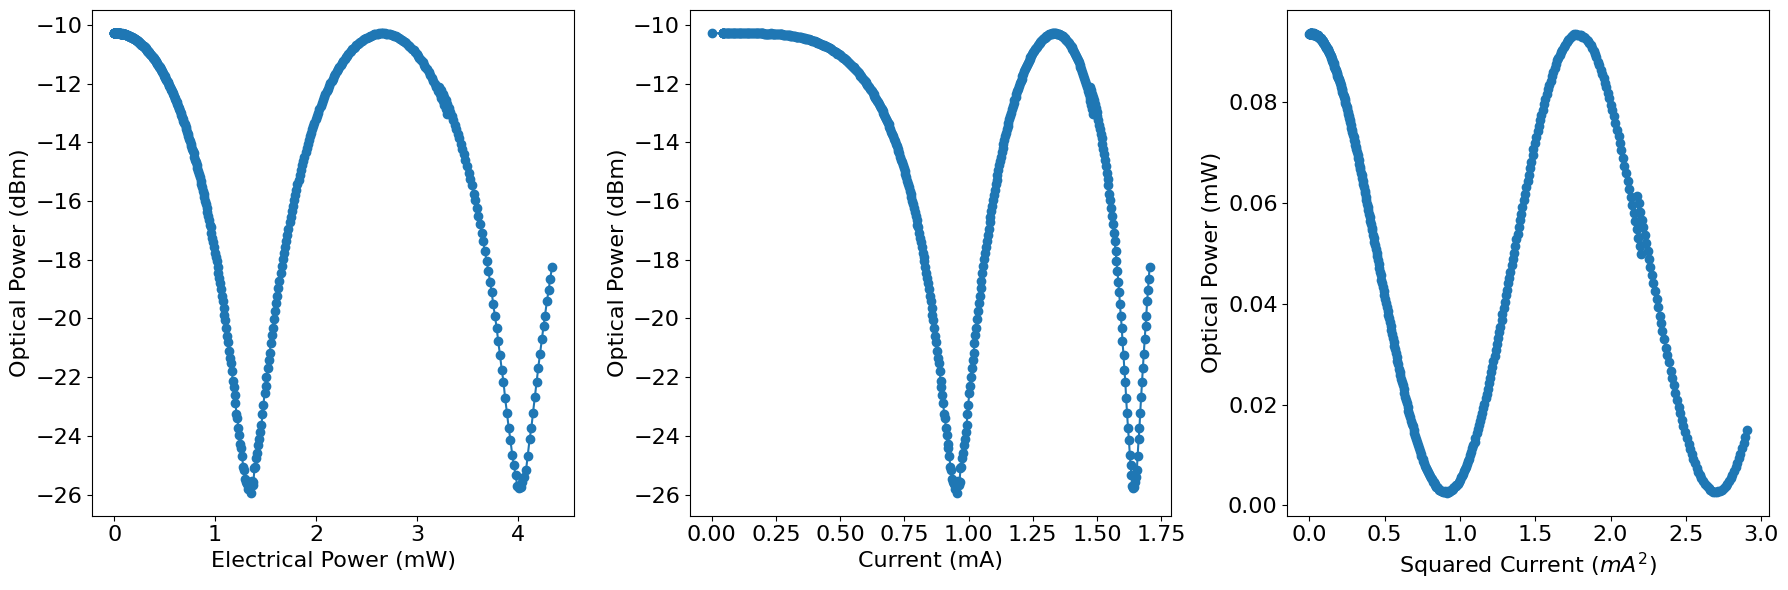

In [11]:
# Convert opower from dBm to linear scale (mW)
opower_linear = 10**(opower/10)

plt.figure(figsize=(18, 6))

# Plot 1: OPower (dBm) vs. IPower (mW)
plt.subplot(1, 3, 1)
plt.plot(ipower, opower, "o-")
plt.xlabel("Electrical Power (mW)", fontsize=16)
plt.ylabel("Optical Power (dBm)", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# Plot 2: OPower (dBm) vs. Current (mA)
plt.subplot(1, 3, 2)
plt.plot(current, opower, "o-")
plt.xlabel("Current (mA)", fontsize=16)
plt.ylabel("Optical Power (dBm)", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# Plot 3: OPower (mW, linear scale) vs. Squared Current (mA^2)
plt.subplot(1, 3, 3)
plt.plot(current**2, opower_linear, "o-")
plt.xlabel("Squared Current ($mA^{2}$)", fontsize=16)
plt.ylabel("Optical Power (mW)", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.tight_layout()
plt.show()

### Fitting

The MZI transfer matrix is:  
$T_{\text{MZI}} = \frac{1}{2}\begin{bmatrix}
e^{i\phi} - 1 & i\,(e^{i\phi} + 1) \\
i\,(e^{i\phi} + 1) & 1 - e^{i\phi}
\end{bmatrix}
= i\,e^{i\phi/2}\begin{bmatrix}
\sin\left(\frac{\phi}{2}\right) & \cos\left(\frac{\phi}{2}\right) \\
\cos\left(\frac{\phi}{2}\right) & -\sin\left(\frac{\phi}{2}\right)
\end{bmatrix}.$

*Note:* The global phase factor $ i\,e^{i\phi/2} $ does not affect the measured intensities and can be omitted if only power ratios are of interest.

#### Measurement Considerations

- **Cross Port:**  
  When measuring the output at the cross port, the intensity is proportional to 
  $ \cos^2\left(\frac{\phi}{2}\right) $.

- **Bar Port:**  
  When measuring at the bar port, the intensity is proportional to 
  $ \sin^2\left(\frac{\phi}{2}\right) $.

In our experimental setup, the measurements are taken at the **cross port**; therefore, the observed output intensity will follow a cosine-squared dependence on the phase shift $ \phi $.

To calibrate the device, we will perform a fit between the experimental data and the theoretical cosine-squared curve. We assume that the phase shift $ \theta $ introduced by the phase shifter is related to the applied current $ I $ by the relation:  
$ \theta = \theta_0 + \alpha I^2 $,  
where:
- $ \theta_0 $ is the initial phase offset due to fabrication imperfections.
- $ \alpha $ is a coefficient that relates the applied current to the induced phase shift.

By fitting the measured intensity data to the model:  
$ P_{\text{out}} \propto \cos^2\left(\frac{\theta_0 + \alpha I^2}{2}\right) $,  
we can extract the parameters $ \theta_0 $ and $ \alpha $. This calibration process will enable us to determine the necessary current to apply in order to achieve a desired phase shift in the MZI.




Fitted parameters:
theta0 = 18.900147091426607
alpha  = -3.5234478281842305
A      = 0.09411295400369107


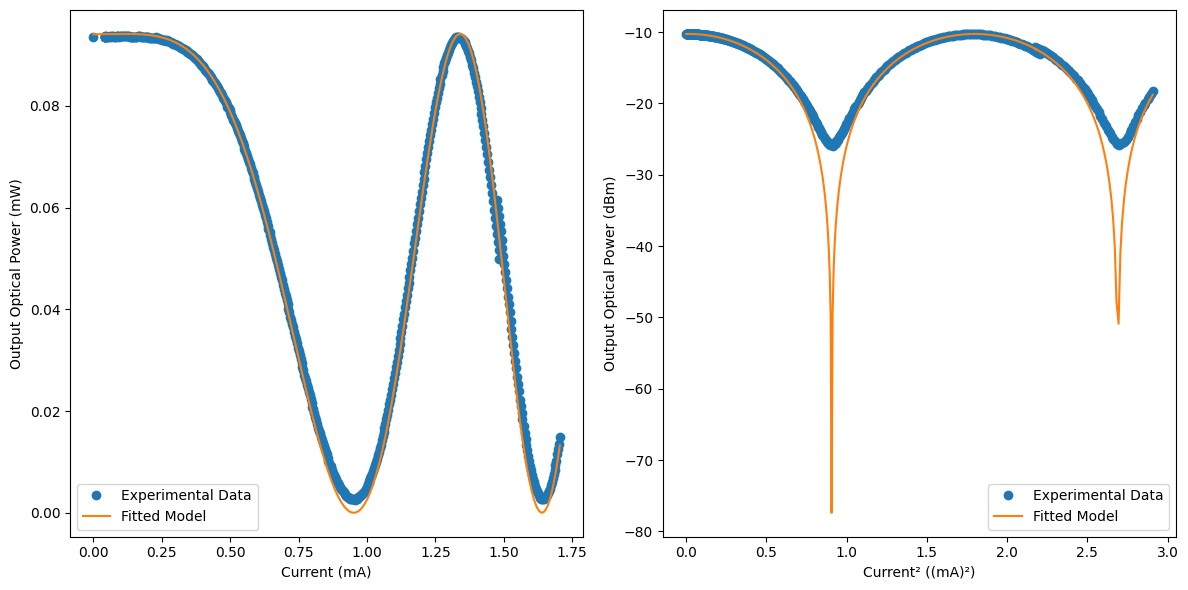

In [12]:
from scipy.optimize import curve_fit
import numpy as np # Por si acaso no se importó en esta celda

# Define the theoretical model for the cross port intensity:
def model(I, theta0, alpha, A):
    return A * np.cos((theta0 + alpha * I**2) / 2)**2

# Provide an initial guess for the parameters: theta0, alpha, and A.
# [theta0 cercana a 0, alpha pequeña, y A es la potencia máxima]
initial_guess = [0.0, 0.05, max(opower_linear)]

# Perform the curve fitting using scipy's curve_fit function
popt, pcov = curve_fit(model, current, opower_linear, p0=initial_guess)
theta0_fit, alpha_fit, A_fit = popt

print("Fitted parameters:")
print("theta0 =", theta0_fit)
print("alpha  =", alpha_fit)
print("A      =", A_fit)

# Generate a smooth curve from the fitted model for visualization
I_fit = np.linspace(min(current), max(current), 200)
fitted_curve = model(I_fit, theta0_fit, alpha_fit, A_fit)

# Convert the measured optical power in linear scale (mW) to dBm.
opower_dBm = 10 * np.log10(np.maximum(opower_linear, 1e-10))

# Create a figure with two subplots:
plt.figure(figsize=(12, 6))

# Subplot 1: Optical power (linear scale, mW) vs. Current (mA)
plt.subplot(1, 2, 1)
plt.plot(current, opower_linear, 'o', label='Experimental Data')
plt.plot(I_fit, fitted_curve, '-', label='Fitted Model')
plt.xlabel("Current (mA)")
plt.ylabel("Output Optical Power (mW)")
plt.legend()

# Subplot 2: Optical power (dBm) vs. Current^2 ((mA)²)
fitted_dBm = 10 * np.log10(np.maximum(model(current, theta0_fit, alpha_fit, A_fit), 1e-10))
plt.subplot(1, 2, 2)
plt.plot(current**2, opower_dBm, 'o', label='Experimental Data')
plt.plot(current**2, fitted_dBm, '-', label='Fitted Model')
plt.xlabel("Current² ((mA)²)")
plt.ylabel("Output Optical Power (dBm)")
plt.legend()

plt.tight_layout()
plt.show()

### Using the Fitted Model to Determine the Required Current

With the parameters obtained from our fitting procedure, we can now use the model to calculate the current required to achieve a specific phase shift, $ \theta $. The relationship between the phase shift and the current is given by:
$$ \theta = \theta_0 + \alpha I^2. $$

Rearranging this equation to solve for the current, we have:
$$ I = \sqrt{\frac{\theta - \theta_0}{\alpha}}. $$

This expression allows us to determine the necessary current to apply in order to obtain a desired phase shift in the MZI.


In [13]:
def calculate_required_current(theta_desired, theta0, alpha):
    import numpy as np

    # If the desired phase shift is less than the initial phase offset, add 2π
    if theta_desired < theta0:
        theta_eff = theta_desired + 2 * np.pi
    else:
        theta_eff = theta_desired

    # Calculate the required current: I = sqrt((theta - theta0) / alpha)
    I_required = np.sqrt((theta_eff - theta0) / alpha)
    
    return I_required


In [14]:
# Give me the solution for theta = np.pi
theta_desired = np.pi  # radians

# Calculate and print the required current
I_required = calculate_required_current(theta_desired, theta0_fit, alpha_fit)

print("For a desired phase shift of {:.2f} radians, the required current is approximately {:.2f} mA.".format(theta_desired, I_required))


For a desired phase shift of 3.14 radians, the required current is approximately 1.64 mA.


In [15]:
# Give me the solution for theta = 0.0
theta_desired = 0 # radians

# Calculate and print the required current
I_required = calculate_required_current(theta_desired, theta0_fit, alpha_fit)

print("For a desired phase shift of {:.2f} radians, the required current is approximately {:.2f} mA.".format(theta_desired, I_required))

For a desired phase shift of 0.00 radians, the required current is approximately 1.89 mA.


## Comments

-- Using the numerical results and the fitting plot, verify whether the obtained currents match our expectations. Check if the MZI output falls in the correct port (cross or bar) as required. --

Vemos que en lineal salvo en la zona de 1,5mW donde los datos de corriente tienen un pequeño desplazamiento matchea bastante bien. Sin embargo, una vez pasamos a dB donde los pequeños cambios se ven amplificados. Esto se debe a que en la vida real pequeños errores de fabricación provoca que ya no sea perfectamente simétrica la división de potencia. Al contrastarlo con el modelo teórico, no tenemos la misma caída a menos infinito que obtenemos en el caso ideal

## **Exercise 4: Part 2**
Repeat the previous results using the file MZI_2.csv and fitting assuming the measurement was performed using the Bar output

Fitted parameters for MZI_2 (Bar Port):
theta0 = -0.7781288872332749
alpha  = 3.5159714995605484
A      = 0.32262404081388185


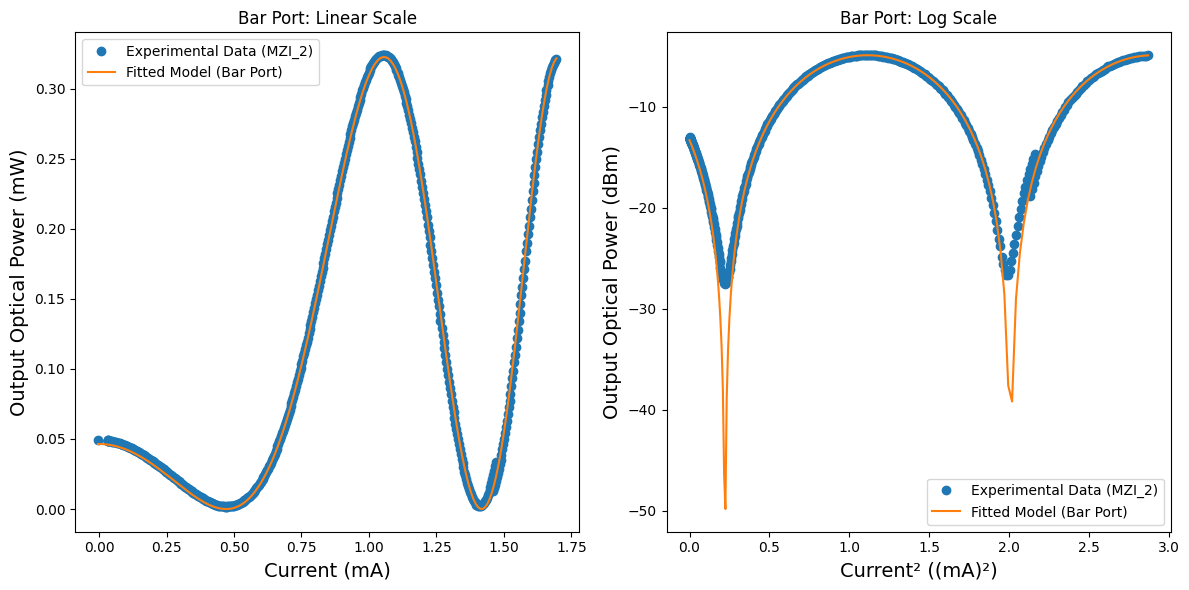

In [20]:

from scipy.optimize import curve_fit

# 1. Cargar los nuevos datos experimentales
data2 = pd.read_csv("MZI_2.csv", index_col=0)
current2 = data2["Current"]
opower2 = data2["OPower"]

# Convertir opower de dBm a escala lineal (mW)
opower_linear2 = 10**(opower2/10)

# 2. Definir el NUEVO modelo teórico para el puerto BAR:
# La intensidad en el puerto Bar es proporcional a sin^2((theta0 + alpha*I^2) / 2)
def model_bar(I, theta0, alpha, A):
    return A * np.sin((theta0 + alpha * I**2) / 2)**2

# 3. Proporcionar un valor inicial estimado y realizar el ajuste de curva
initial_guess2 = [0.0, 0.05, max(opower_linear2)]
popt2, pcov2 = curve_fit(model_bar, current2, opower_linear2, p0=initial_guess2)
theta0_fit2, alpha_fit2, A_fit2 = popt2

print("Fitted parameters for MZI_2 (Bar Port):")
print("theta0 =", theta0_fit2)
print("alpha  =", alpha_fit2)
print("A      =", A_fit2)

# 4. Generar una curva suave a partir del modelo ajustado para la visualización (200 puntos)
I_fit2 = np.linspace(min(current2), max(current2), 200)
fitted_curve2 = model_bar(I_fit2, theta0_fit2, alpha_fit2, A_fit2)

# Convertir a dBm para graficar (evitando el logaritmo de cero)
opower_dBm2 = 10 * np.log10(np.maximum(opower_linear2, 1e-10))
fitted_dBm2 = 10 * np.log10(np.maximum(fitted_curve2, 1e-10))

# 5. Crear las gráficas
plt.figure(figsize=(12, 6))

# Subplot 1: Potencia óptica (escala lineal, mW) vs. Corriente (mA)
plt.subplot(1, 2, 1)
plt.plot(current2, opower_linear2, 'o', label='Experimental Data (MZI_2)')
plt.plot(I_fit2, fitted_curve2, '-', label='Fitted Model (Bar Port)')
plt.xlabel("Current (mA)", fontsize=14)
plt.ylabel("Output Optical Power (mW)", fontsize=14)
plt.title("Bar Port: Linear Scale")
plt.legend()

# Subplot 2: Potencia óptica (dBm) vs. Corriente al cuadrado ((mA)²)
# ---> ¡Aquí está la corrección aplicada: I_fit2**2 ! <---
plt.subplot(1, 2, 2)
plt.plot(current2**2, opower_dBm2, 'o', label='Experimental Data (MZI_2)')
plt.plot(I_fit2**2, fitted_dBm2, '-', label='Fitted Model (Bar Port)')
plt.xlabel("Current² ((mA)²)", fontsize=14)
plt.ylabel("Output Optical Power (dBm)", fontsize=14)
plt.title("Bar Port: Log Scale")
plt.legend()

plt.tight_layout()
plt.show()

In [21]:

# Solución para theta = 0.0
theta_desired_0 = 0.0
I_required_0 = calculate_required_current(theta_desired_0, theta0_fit2, alpha_fit2)
print("MZI_2 (Bar) -> For a desired phase shift of {:.2f} radians, the required current is approximately {:.2f} mA.".format(theta_desired_0, I_required_0))

# Solución para theta = np.pi
theta_desired_pi = np.pi
I_required_pi = calculate_required_current(theta_desired_pi, theta0_fit2, alpha_fit2)
print("MZI_2 (Bar) -> For a desired phase shift of {:.2f} radians, the required current is approximately {:.2f} mA.".format(theta_desired_pi, I_required_pi))

MZI_2 (Bar) -> For a desired phase shift of 0.00 radians, the required current is approximately 0.47 mA.
MZI_2 (Bar) -> For a desired phase shift of 3.14 radians, the required current is approximately 1.06 mA.


**End of the notebook. Thanks for your contribution**